<div style="border: 3px solid #0d3b0d; border-radius: 10px; overflow: hidden; margin-bottom: 20px; font-family: Arial, sans-serif;">

  <!-- Banner Institucional -->
  <div style="background-color: #006633; padding: 0;">
    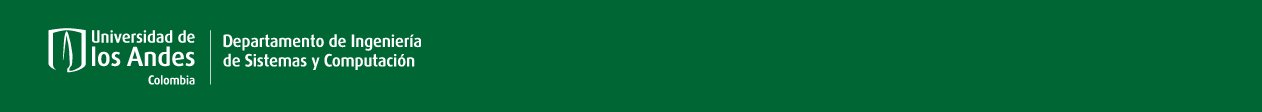
  </div>

  <!-- Titulo del laboratorio -->
  <div style="background-color: #ffffff; padding: 15px 20px; text-align: center;">
    <h2 style="margin: 0; color: #1a1a1a; font-size: 18px;">AI Security - Laboratorio 6 · Sesión 14</h2>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 13px;">Defensa Mediante Entrenamiento Adversarial y Robustecimiento de Modelos</p>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 12px;">Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI)</p>
  </div>

  <!-- Aviso de propiedad intelectual -->
  <div style="background-color: #f5f5f0; padding: 12px 20px; border-top: 1px solid #ddd; font-size: 11px; color: #444; line-height: 1.5;">
    <strong>Propiedad Intelectual - Universidad de los Andes</strong><br>
    Este material es propiedad exclusiva de la Universidad de los Andes (Bogot&aacute;, Colombia) y ha sido desarrollado para el programa de Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI), Departamento de Ingenier&iacute;a de Sistemas y Computaci&oacute;n. Todos los derechos reservados &copy; 2026.<br><br>
    <strong>Condiciones de uso:</strong> Este material se distribuye exclusivamente a los estudiantes matriculados en el curso AI Security del programa MESI y est&aacute; protegido por las leyes colombianas de derechos de autor (Ley 23 de 1982 y Ley 1915 de 2018) y por las disposiciones aplicables de propiedad intelectual de la Universidad de los Andes. Queda estrictamente prohibida su reproducci&oacute;n, distribuci&oacute;n, modificaci&oacute;n, publicaci&oacute;n o transmisi&oacute;n total o parcial, en cualquier forma o medio, sin la autorizaci&oacute;n previa y por escrito de la Universidad de los Andes. El incumplimiento de estas condiciones podr&aacute; dar lugar a las acciones disciplinarias, civiles y penales correspondientes.
  </div>

</div>

# **Laboratorio 6 · Sesión 14: Defensa Mediante Entrenamiento Adversarial y Robustecimiento de Modelos**

**Curso:** AI Security - MESI    


## **Objetivos de Aprendizaje**

Al completar este laboratorio, el estudiante será capaz de:

1. Comprender las estrategias de defensa contra ataques adversariales en modelos de Deep Learning
2. Implementar entrenamiento adversarial (Adversarial Training) utilizando PGD cómo mecanismo de robustecimiento
3. Aplicar destilación defensiva (Defensive Distillation) cómo técnica complementaria de defensa
4. Implementar preprocesamiento de entradas (Feature Squeezing) cómo defensa sin re-entrenamiento
5. Evaluar cuantitativamente el trade-off entre precisión en datos limpios y robustez adversarial
6. Comparar sistematicamente la efectividad de multiples estrategias de defensa

---

## **Aviso Legal y Uso de Datos**

### **Propósito Académico**

Este laboratorio se desarrolla exclusivamente con **fines académicos y educativos** en el marco del curso de AI Security de la Maestría en Seguridad de la Información (MESI) de la Universidad de los Andes. El contenido, técnicas y herramientas presentadas están diseñadas para la enseñanza de conceptos de Machine Learning aplicados a ciberseguridad.

### **Datos Utilizados**

Todos los datasets empleados en este laboratorio son de **uso libre y público**:

- **CIFAR-10:** Dataset de referencia para clasificación de imágenes
  - Fuente: Canadian Institute For Advanced Research
  - Licencia: Uso libre para investigación y educación
  - Contenido: 60,000 imágenes de 32x32 pixeles en 10 clases

### **Limitaciones y Responsabilidad**

- Los modelos y defensas desarrollados en este laboratorio son para **propósitos educativos** únicamente
- No deben ser desplegados en entornos de producción sin validación y pruebas exhaustivas adicionales
- El uso indebido de las técnicas aqui presentadas es responsabilidad exclusiva del usuario
- Este material se rige por las políticas académicas de la Universidad de los Andes

---

## **Metodología: Ciclo CRISP-DM**

Este laboratorio sigue la métodología **CRISP-DM (Cross-Industry Standard Process for Data Mining)**, el estándar de la industria para proyectos de Machine Learning:

1. **Comprensión del Negocio (Business Understanding):** Entender la necesidad de defender modelos de IA contra ataques adversariales
2. **Comprensión de los Datos (Data Understanding):** Explorar CIFAR-10 y los efectos de perturbaciónes adversariales
3. **Preparación de los Datos (Data Preparation):** Generación de ejemplos adversariales para entrenamiento robusto
4. **Modelado (Modeling):** Implementación de defensas: Adversarial Training, Destilación Defensiva y Feature Squeezing
5. **Evaluación (Evaluation):** Comparación sistematica de robustez bajo multiples ataques
6. **Despliegue (Deployment):** Consideraciones para implementación de defensas en producción

A medida que avance en el laboratorio, identifique en que fase de CRISP-DM se encuentra en cada sección.

## **Contexto: ¿Por qué Defender Modelos de IA?**

En el Laboratorio 4 exploramos cómo los ataques adversariales (FGSM, BIM, PGD) pueden engañar a clasificadores de Deep Learning con perturbaciones imperceptibles. En escenarios reales de ciberseguridad, esto representa una amenaza crítica:

- **Evasión de malware:** Un atacante puede modificar ligeramente un binario malicioso para evadir un clasificador basado en CNN.
- **Evasión de NIDS:** Perturbaciones en el tráfico de red pueden burlar sistemas de detección de intrusiones.
- **Ataques a sistemas autónomos:** Modificaciones imperceptibles en señales de tránsito pueden causar accidentes.

### **Estrategias de Defensa**

Las defensas contra ataques adversariales se clasifican en tres grandes categorias:

1. **Modificación del entrenamiento:** Entrenamiento adversarial (PGD-AT), TRADES.
2. **Modificación de la arquitectura/modelo:** Destilación defensiva, suavizado de la superficie de decisión.
3. **Preprocesamiento de entradas:** Feature Squeezing, reducción de profundidad de bits, suavizado espacial.

### **Nuestro objetivo:**
Implementar y comparar estas tres estrategias de defensa, evaluando cuantitativamente su efectividad y el trade-off entre precisión limpia y robustez adversarial.

---

## **1. Configuración del Entorno**

Instalamos las librerias necesarias para este laboratorio.

In [ ]:
import os
import sys

# Agrega la ruta de ejecutables y paquetes locales al PATH y sys.path del sistema
local_bin = os.path.expanduser("~/.local/bin")
if local_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{local_bin}:{os.environ['PATH']}"

user_site = os.path.expanduser("~/.local/lib/python3.10/site-packages")
if user_site not in sys.path:
    sys.path.append(user_site)

# transformer_engine (preinstalado en la imagen del servidor) no se usa y puede romper
# importaciones en cadena: se marca como no disponible. torchvision NO se bloquea aqui
# porque RobustBench (Seccion 8.4) lo necesita.
for _m in ("transformer_engine", "transformer_engine_extensions"):
    sys.modules[_m] = None

In [ ]:
# Instalacion de dependencias SIN reemplazar TensorFlow / PyTorch / NumPy del servidor.
# El servidor trae builds especiales de TensorFlow y PyTorch compilados para su driver de
# GPU (CUDA 12.4). Un `pip install tensorflow` (o un paquete que arrastre torch) instala en
# ~/.local versiones nuevas que no ven la GPU. Esta celda:
#   1) quita de ~/.local cualquier PyTorch que tape al del servidor;
#   2) comprueba que TensorFlow vea la GPU y, si no, quita el TensorFlow de ~/.local;
#   3) instala solo lo que falta fijando las versiones del servidor (tambien para RobustBench).
import os, sys, subprocess
from importlib.metadata import distributions

USER_SITE = os.path.expanduser("~/.local/lib/python3.10/site-packages")
PIP = [sys.executable, "-m", "pip"]
PROBE_TF = ("import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'; import tensorflow as tf; "
            "print('PROBE', tf.__version__, '|', tf.__file__, '|', "
            "len(tf.config.list_physical_devices('GPU')))")
PROBE_TORCH = ("import torch; print('PROBE', torch.__version__, '|', torch.__file__, '|', "
               "int(torch.cuda.is_available()))")

def probar(codigo):
    r = subprocess.run([sys.executable, "-c", codigo], capture_output=True, text=True)
    for linea in r.stdout.splitlines():
        if linea.startswith("PROBE"):
            ver, ruta, ngpu = [s.strip() for s in linea[len("PROBE"):].split("|")]
            return {"version": ver, "ruta": ruta, "gpus": int(ngpu)}, ""
    return None, r.stderr[-2500:]

def paquetes_user_site():
    if not os.path.isdir(USER_SITE):
        return {}
    return {(d.metadata["Name"] or "").lower(): d.version for d in distributions(path=[USER_SITE])}

def desinstalar(nombres):
    if nombres:
        print("Desinstalando de ~/.local:", nombres)
        subprocess.run(PIP + ["uninstall", "-y", "-q", *nombres], check=False)

# 1) PyTorch de ~/.local fuera (RobustBench usara el del servidor), con sus librerias nvidia-*
if "torch" in paquetes_user_site():
    desinstalar(sorted(n for n in paquetes_user_site()
                       if n in {"torch", "torchvision", "torchaudio", "triton"} or n.startswith("nvidia-")))

# 2) TensorFlow con GPU
info_tf, err = probar(PROBE_TF)
print("TensorFlow detectado:", info_tf)
if info_tf is None or info_tf["gpus"] == 0:
    pref = ("tensorflow", "tf-keras", "tf_keras", "keras", "tensorboard", "ml-dtypes", "ml_dtypes", "nvidia-")
    desinstalar(sorted(n for n in paquetes_user_site() if n.startswith(pref)))
    info_tf, err = probar(PROBE_TF)
    if info_tf is None and "numpy" in err.lower() and "numpy" in paquetes_user_site():
        desinstalar(["numpy"])
        info_tf, err = probar(PROBE_TF)
    print("TensorFlow tras la limpieza:", info_tf)
if info_tf is None or info_tf["gpus"] == 0:
    print(err)
    raise RuntimeError(
        "TensorFlow no detecta la GPU. Ejecute en una celda:\n"
        "  !nvidia-smi; pip list --user | grep -i -E 'tensorflow|keras|numpy|nvidia|torch'\n"
        "y comparta la salida.")

info_torch, _ = probar(PROBE_TORCH)
print("PyTorch detectado:", info_torch)

# 3) Fijar versiones del servidor (el archivo se reutiliza al instalar RobustBench)
FIJAR = {"tensorflow", "keras", "tf-keras", "numpy", "torch", "torchvision", "ml-dtypes",
         "tensorboard", "protobuf", "h5py"}
freeze = subprocess.run(PIP + ["list", "--format=freeze"], capture_output=True, text=True).stdout
RESTRICCIONES = os.path.expanduser("~/lab6_constraints.txt")
with open(RESTRICCIONES, "w") as f:
    for linea in freeze.splitlines():
        if "==" in linea and linea.split("==")[0].lower() in FIJAR:
            f.write(linea + "\n")
print("Versiones fijadas:\n" + open(RESTRICCIONES).read())

subprocess.run(PIP + ["install", "-q", "--user", "-c", RESTRICCIONES,
                      "adversarial-robustness-toolbox", "matplotlib", "scikit-learn",
                      "scipy", "pandas",
                      # ART importa `multiprocess` en AutoAttack.generate pero no lo declara
                      "multiprocess"], check=True)

info_tf, err = probar(PROBE_TF)
print("Verificacion final TensorFlow:", info_tf)
if info_tf is None or info_tf["gpus"] == 0:
    print(err)
    raise RuntimeError("La instalacion dejo a TensorFlow sin GPU; comparta esta salida.")
print("\nListo. Reinicie el kernel (Kernel -> Restart) y continue desde la celda 1 "
      "SIN volver a ejecutar esta celda.")

Importaciones

In [ ]:
# Importaciones del laboratorio
import os
import gc
import time
import warnings

# Nivel de logs de TensorFlow (debe fijarse antes de importarlo): 2 = solo errores
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Manejo de datos y visualizacion
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter   # filtro de mediana para feature squeezing

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, BatchNormalization, MaxPooling2D, Dropout,
                                     Flatten, Dense, Activation, Rescaling)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Adversarial Robustness Toolbox (ART)
import art
from art.estimators.classification import TensorFlowV2Classifier
from art.attacks.evasion import (FastGradientMethod, ProjectedGradientDescent, CarliniL2Method,
                                 SquareAttack, AutoAttack, AutoProjectedGradientDescent)
# ART tambien ofrece defensas de preprocesamiento listas (art.defences.preprocessor:
# FeatureSqueezing, SpatialSmoothing); aqui se implementan a mano en la Seccion 7.
from art.defences.preprocessor import FeatureSqueezing, SpatialSmoothing

# Crecimiento dinamico de memoria en GPU
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"No se pudo habilitar memory growth en {gpu.name}: {e}")

# El laboratorio debe correr en GPU: si TensorFlow no la ve, se detiene aqui
if not gpus:
    raise RuntimeError(
        "TensorFlow no detecta la GPU. Ejecute la celda de instalacion (corrige la "
        "instalacion), reinicie el kernel y vuelva a correr desde la celda 1.")

# Salida limpia
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# Semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"TensorFlow: {tf.__version__}  ({tf.__file__})")
print(f"ART:        {art.__version__}")
print(f"GPUs disponibles: {len(gpus)} -> {[g.name for g in gpus]}")

### **Documentación de Librerias:**
Si no esta familiarizado con alguna libreria, consulte:
- [ART - Adversarial Robustness Toolbox](https://adversarial-robustness-toolbox.readthedocs.io/) - Documentación oficial
- [TensorFlow/Keras - Guia oficial](https://www.tensorflow.org/guide)
- [Matplotlib - Galería de ejemplos](https://matplotlib.org/stable/gallery/index.html)

---

## **2. Comprensión y Preparación de los Datos**

Utilizaremos el dataset **CIFAR-10** como benchmark. Este dataset es el estándar en la literatura de robustez adversarial (Madry et al., 2018; Zhang et al., 2019) lo que permite a los estudiantes contrastar directamente sus resultados con los reportados en publicaciones académicas.

**Justificación del dataset:** A diferencia del modelo Malimg usado en laboratorios anteriores (25 familias, imágenes de mayor resolución), CIFAR-10 ofrece imágenes de 32x32 pixeles con 10 clases. Esto permite que los ciclos de entrenamiento adversarial (que requieren generar perturbaciónes en cada epoca) sean computacionalmente viables.

In [ ]:
# Carga del dataset CIFAR-10
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = cifar10.load_data()

# Nombres de las clases
CIFAR10_CLASSES = [
    'avion', 'automovil', 'pajaro', 'gato', 'ciervo',
    'perro', 'rana', 'caballo', 'barco', 'camion'
]

print(f"Datos de entrenamiento: {x_train_raw.shape}")
print(f"Datos de prueba: {x_test_raw.shape}")
print(f"Rango de valores original: [{x_train_raw.min()}, {x_train_raw.max()}]")
print(f"Clases: {len(CIFAR10_CLASSES)}")

### **2.1 Preprocesamiento**

Normalizamos las imágenes al rango [0, 1], que es el rango estándar para trabajar con la libreria ART y con los ataques adversariales basados en gradientes.

In [ ]:
# Normalización al rango [0, 1]
x_train = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0

# One-hot encoding de las etiquetas
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

print(f"Rango de valores normalizado: [{x_train.min()}, {x_train.max()}]")
print(f"Forma de etiquetas (one-hot): {y_train.shape}")

### **2.2 Visualización exploratoria**

Visualicemos algunas muestras del dataset para entender los datos con los que trabajaremos.

In [ ]:
# Visualización de muestras por clase
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Muestras de CIFAR-10 por Clase', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_raw.flatten() == i)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(CIFAR10_CLASSES[i], fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

# Distribución de clases
unique, counts = np.unique(y_train_raw, return_counts=True)
print("Distribución de clases en entrenamiento:")
for cls, cnt in zip(CIFAR10_CLASSES, counts):
    print(f"  {cls}: {cnt} muestras")

---

## **3. Construcción del Modelo Base (Línea Base)**

Construiremos una CNN desde cero que servira cómo nuestro **modelo base sin defensas**. Este modelo sera la referencia contra la cual mediremos la mejora de cada estrategia de defensa.

La arquitectura sigue un patrón estándar de CNN con bloques convolucionales progresivos, BatchNormalization para estabilidad del entrenamiento, y Dropout para regularización.

In [ ]:
def build_cifar10_model():
    """Construye una CNN para clasificación de CIFAR-10.

    Arquitectura: 3 bloques convolucionales + 2 capas densas.
    Usa BatchNormalization y Dropout para regularización.
    """
    model = Sequential([
        # Bloque convolucional 1
        Conv2D(32, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal', input_shape=(32, 32, 3)),
        BatchNormalization(),
        Conv2D(32, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.2),

        # Bloque convolucional 2
        Conv2D(64, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        Conv2D(64, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.3),

        # Bloque convolucional 3
        Conv2D(128, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        Conv2D(128, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.4),

        # Clasificador
        Flatten(),
        Dense(256, activation='relu', kernel_initializer='he_normal'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])

    return model

# Construcción del modelo base
model_base = build_cifar10_model()
model_base.summary()

### **3.1 Entrenamiento del Modelo Base**

In [ ]:
# MODELO BASE: DOS MODOS DE USO (desechable o persistente)
#
#   USAR_MODELO_PERSISTENTE = False -> DESECHABLE: reentrena siempre desde cero.
#                                      Recomendado la primera vez (ejercicio completo).
#   USAR_MODELO_PERSISTENTE = True  -> PERSISTENTE: carga el modelo guardado si existe;
#                                      si no existe, lo entrena y lo guarda.

from tensorflow.keras.models import load_model

BASE_MODEL_PATH = 'base_cifar10.h5'
USAR_MODELO_PERSISTENTE = False   # cambia a True para cargar el modelo ya entrenado

if USAR_MODELO_PERSISTENTE and os.path.exists(BASE_MODEL_PATH):
    model_base = load_model(BASE_MODEL_PATH)
    history_base = None   # al cargar no hay historial de entrenamiento (ver nota abajo)
    print(f"Modo PERSISTENTE: modelo base cargado desde {BASE_MODEL_PATH}")
else:
    if USAR_MODELO_PERSISTENTE:
        print("Modo PERSISTENTE solicitado, pero no existe artefacto previo.")
        print("Se entrena el modelo base por primera vez y se guarda.")
    else:
        print("Modo DESECHABLE: se entrena el modelo base desde cero.")

    model_base.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    callbacks_base = [
        EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
    ]
    print("Entrenando modelo base (sin defensas)...")
    history_base = model_base.fit(
        x_train, y_train,
        epochs=50, batch_size=128, validation_split=0.1,
        callbacks=callbacks_base, verbose=1
    )
    model_base.save(BASE_MODEL_PATH)
    print(f"Modelo base guardado en {BASE_MODEL_PATH} (disponible para el modo persistente).")

# Evaluacion en datos limpios (comun a ambos modos)
loss_base, acc_base = model_base.evaluate(x_test, y_test, verbose=0)
print(f"\nModelo base - Accuracy en datos limpios: {acc_base:.4f}")

### **3.2 Curvas de Entrenamiento**

In [ ]:
# Curvas de entrenamiento del modelo base
if history_base is None:
    print("El modelo base se cargo desde disco (modo persistente): no hay historial de "
          "entrenamiento que graficar. Use USAR_MODELO_PERSISTENTE = False para verlo.")
else:
    h = history_base.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(h['accuracy'], label='Entrenamiento', linewidth=2)
    ax1.plot(h['val_accuracy'], label='Validacion', linewidth=2)
    ax1.set_title('Accuracy del modelo base', fontweight='bold')
    ax1.set_xlabel('Epoca'); ax1.set_ylabel('Accuracy'); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(h['loss'], label='Entrenamiento', linewidth=2)
    ax2.plot(h['val_loss'], label='Validacion', linewidth=2)
    ax2.set_title('Loss del modelo base', fontweight='bold')
    ax2.set_xlabel('Epoca'); ax2.set_ylabel('Loss'); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    mejor = int(np.argmax(h['val_accuracy']))
    print(f"Epocas ejecutadas: {len(h['accuracy'])} (mejor val_accuracy en la epoca {mejor + 1}: "
          f"{h['val_accuracy'][mejor]:.4f})")
    print(f"Gap final train - val: {h['accuracy'][-1] - h['val_accuracy'][-1]:+.4f}")

---

## **4. Evaluacion de Vulnerabilidad del Modelo Base**

Antes de implementar defensas, necesitamos cuantificar que tan vulnerable es nuestro modelo base frente a diferentes ataques adversariales. Esto nos dara una linea base de referencia.

Utilizaremos cuatro ataques representativos que cubren diferentes categorias de amenazas:

**Ataques de caja blanca (white-box):**
- **FGSM** (Fast Gradient Sign Method): Ataque de un solo paso, rapido pero menos potente
- **PGD** (Projected Gradient Descent): Ataque iterativo, considerado el adversario de primer orden mas fuerte
- **C&W L2** (Carlini & Wagner): Ataque basado en optimizacion, disenado para encontrar perturbaciones minimas. Es uno de los ataques mas efectivos conocidos y fue clave para demostrar la debilidad de la destilacion defensiva (Carlini & Wagner, 2017)

**Ataque de caja negra (black-box):**
- **Square Attack**: Ataque basado en consultas (score-based) que no requiere acceso a los gradientes del modelo. Representa una amenaza mas realista en escenarios de produccion donde el atacante no tiene acceso al modelo interno

### **4.1 Configuración del Clasificador ART**

Envolvemos nuestro modelo de Keras en un clasificador de ART para poder utilizar sus ataques y defensas.

In [ ]:
# Crear la función de pérdida
loss_fn = CategoricalCrossentropy()

# Envolver el modelo base en un clasificador ART
classifier_base = TensorFlowV2Classifier(
    model=model_base,
    nb_classes=10,
    input_shape=(32, 32, 3),
    loss_object=loss_fn,
    clip_values=(0.0, 1.0)
)

print("Clasificador ART configurado exitosamente.")
print(f"Forma de entrada: {classifier_base.input_shape}")
print(f"Número de clases: {classifier_base.nb_classes}")

### **4.2 Generacion de Ataques Adversariales**

Generamos ejemplos adversariales con los cuatro ataques sobre un subconjunto de prueba para evaluar la vulnerabilidad del modelo base.

**Parametros estandar de la literatura:**
- **FGSM:** epsilon = 8/255 (norma L-infinito)
- **PGD:** epsilon = 8/255, paso = 2/255, 20 iteraciones
- **C&W L2:** learning rate = 0.01, 100 iteraciones, busqueda binaria de 5 pasos
- **Square Attack:** epsilon = 8/255, 1000 consultas

**Nota:** C&W L2 es computacionalmente costoso, por lo que se evalua sobre un subconjunto reducido de 200 muestras. Para los demas ataques se usan 1000 muestras.

In [ ]:
# Subconjunto para evaluacion (reducir costo computacional)
N_EVAL = 1000
N_EVAL_CW = 200  # C&W es costoso, usamos un subconjunto menor
x_test_subset = x_test[:N_EVAL]
y_test_subset = y_test[:N_EVAL]
x_test_subset_cw = x_test[:N_EVAL_CW]
y_test_subset_cw = y_test[:N_EVAL_CW]

# Parametros de ataque (estandar en la literatura)
EPS = 8.0 / 255.0  # Presupuesto de perturbacion
EPS_STEP = 2.0 / 255.0  # Tamano de paso para ataques iterativos

print("Generando ataques adversariales contra el modelo base...")
print(f"Epsilon (presupuesto de perturbacion): {EPS:.4f}")
print(f"Subconjunto de evaluacion: {N_EVAL} muestras (C&W: {N_EVAL_CW})")
print()

# --- FGSM (White-box, un paso) ---
print("[1/4] Generando ataque FGSM...")
attack_fgsm = FastGradientMethod(
    estimator=classifier_base,
    eps=EPS,
    norm=np.inf
)
x_test_fgsm = attack_fgsm.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_fgsm - x_test_subset)):.4f}")

# --- PGD (White-box, iterativo) ---
print("[2/4] Generando ataque PGD (20 iteraciones)...")
attack_pgd = ProjectedGradientDescent(
    estimator=classifier_base,
    eps=EPS,
    eps_step=EPS_STEP,
    max_iter=20,
    norm=np.inf
)
x_test_pgd = attack_pgd.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_pgd - x_test_subset)):.4f}")

# --- C&W L2 (White-box, basado en optimizacion) ---
print("[3/4] Generando ataque C&W L2 (200 muestras)...")
print("  Esto puede tomar varios minutos...")
attack_cw = CarliniL2Method(
    classifier=classifier_base,
    confidence=0.0,
    max_iter=100,
    learning_rate=0.01,
    binary_search_steps=5,
    batch_size=N_EVAL_CW,  # un solo lote: mismo ataque (ART ajusta cada muestra por separado), mucho mas rapido
    verbose=False
)
x_test_cw = attack_cw.generate(x=x_test_subset_cw)
perturbacion_cw_l2 = np.mean(np.sqrt(np.sum((x_test_cw - x_test_subset_cw) ** 2, axis=(1, 2, 3))))
print(f"  Perturbacion promedio L2: {perturbacion_cw_l2:.4f}")

# --- Square Attack (Black-box, basado en consultas) ---
print("[4/4] Generando ataque Square Attack (black-box)...")
attack_square = SquareAttack(
    estimator=classifier_base,
    eps=EPS,
    norm=np.inf,
    max_iter=1000,
    batch_size=128,
    verbose=False
)
x_test_square = attack_square.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_square - x_test_subset)):.4f}")

print("\nGeneracion de ataques completada.")

### **4.3 Impacto de los Ataques en el Modelo Base**

In [ ]:
def evaluate_accuracy(classifier, x_data, y_data, nombre=""):
    """Accuracy de un clasificador ART; y_data viene en one-hot."""
    preds = classifier.predict(x_data, batch_size=256)
    acc = float(np.mean(np.argmax(preds, axis=1) == np.argmax(y_data, axis=1)))
    if nombre:
        print(f"  {nombre:<26s}: {acc:.4f} ({acc * 100:.2f}%)")
    return acc

print("MODELO BASE - accuracy en datos limpios y bajo ataque")
print("=" * 60)
acc_clean = evaluate_accuracy(classifier_base, x_test_subset, y_test_subset, "Limpio")
acc_fgsm = evaluate_accuracy(classifier_base, x_test_fgsm, y_test_subset, "FGSM")
acc_pgd = evaluate_accuracy(classifier_base, x_test_pgd, y_test_subset, "PGD-20")
acc_cw = evaluate_accuracy(classifier_base, x_test_cw, y_test_subset_cw, "C&W L2 (200 muestras)")
acc_square = evaluate_accuracy(classifier_base, x_test_square, y_test_subset, "Square Attack")

# C&W se compara contra la accuracy limpia de SU propio subconjunto
acc_clean_cw = evaluate_accuracy(classifier_base, x_test_subset_cw, y_test_subset_cw)
print("\nCaida de accuracy por ataque (puntos porcentuales):")
for nombre, acc, ref in [("FGSM", acc_fgsm, acc_clean), ("PGD-20", acc_pgd, acc_clean),
                         ("C&W L2", acc_cw, acc_clean_cw), ("Square Attack", acc_square, acc_clean)]:
    print(f"  {nombre:<14s}: -{(ref - acc) * 100:.2f} pp")

### **4.4 Visualización de Ejemplos Adversariales**

In [ ]:
# Originales vs adversariales (prediccion del modelo base: verde = correcta, rojo = incorrecta)
N_MOSTRAR = 6
filas = [("Original", x_test_subset), ("FGSM", x_test_fgsm),
         ("PGD-20", x_test_pgd), ("Square", x_test_square)]
y_real = np.argmax(y_test_subset[:N_MOSTRAR], axis=1)

fig, axes = plt.subplots(len(filas), N_MOSTRAR, figsize=(2.3 * N_MOSTRAR, 2.5 * len(filas)))
for r, (nombre, datos) in enumerate(filas):
    preds = np.argmax(classifier_base.predict(datos[:N_MOSTRAR]), axis=1)
    for c in range(N_MOSTRAR):
        ax = axes[r, c]
        ax.imshow(np.clip(datos[c], 0, 1))
        ax.set_title(CIFAR10_CLASSES[preds[c]], fontsize=10,
                     color='green' if preds[c] == y_real[c] else 'red')
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(nombre, fontsize=11, fontweight='bold')
plt.suptitle(f'Ejemplos adversariales (eps = 8/255) - real: '
             f'{", ".join(CIFAR10_CLASSES[i] for i in y_real)}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

---

## **5. Defensa 1: Entrenamiento Adversarial (Adversarial Training)**

El **entrenamiento adversarial** es considerado una de las defensas más efectivas y robustas contra ataques de evasión. La idea central es incluir ejemplos adversariales generados durante el proceso de entrenamiento, forzando al modelo a aprender a clasificar correctamente tanto datos limpios cómo datos perturbados.

### **Formulación Matemática**

El entrenamiento adversarial con PGD se formula cómo un problema de **optimización minimax** (Madry et al., 2018):

$$\min_{\theta} \mathbb{E}_{(x,y) \sim D} \left[ \max_{\delta \in S} L(f_\theta(x + \delta), y) \right]$$

Donde:
- $\theta$: Parámetros del modelo
- $\delta$: Perturbación adversarial dentro del conjunto permitido $S = \{\delta : \|\delta\|_\infty \leq \epsilon\}$
- $L$: Función de pérdida (cross-entropy)
- La **maximización interna** busca la peor perturbación (via PGD)
- La **minimización externa** entrena el modelo para ser robusto ante esa perturbación

### **Trade-off Accuracy vs. Robustez**

Un hallazgo teorico fundamental (Zhang et al., 2019 - ICML) es que existe un trade-off inherente entre la precisión en datos limpios y la robustez adversarial. El método TRADES formaliza este trade-off cómo una pérdida regularizada. En la practica, el entrenamiento adversarial tipicamente reduce la accuracy limpia entre 5-15 puntos porcentuales, pero incrementa significativamente la robustez.

### **El frente actual: datos sintéticos y RobustBench**

El entrenamiento adversarial sigue siendo la base de las defensas empíricas más fuertes, pero desde 2021 el mayor avance no viene de nuevas funciones de pérdida, sino de **aumentar los datos de entrenamiento con muestras generadas por modelos de difusión** (Wang et al., 2023). Los modelos que lideran hoy el benchmark de referencia **RobustBench** en CIFAR-10 usan esta estrategia, alcanzando alrededor de 73-74% de robustez bajo AutoAttack (epsilon = 8/255), frente a más de 90% de accuracy en datos limpios (Bartoldson et al., 2024).

Otras mejoras al entrenamiento adversarial que vale la pena conocer son TRADES (que ya mencionamos), MART (que da trato especial a los ejemplos mal clasificados) y AWP (Adversarial Weight Perturbation, que perturba también los pesos para aplanar la superficie de pérdida). El leaderboard en vivo de RobustBench (https://robustbench.github.io/) mantiene el ranking actualizado.

### **5.1 Implementacion del Entrenamiento Adversarial**

La implementacion del entrenamiento adversarial consta de dos pasos:

1. **Generacion de ejemplos adversariales:** Utilizamos PGD para generar un conjunto de ejemplos adversariales a partir de un subconjunto de los datos de entrenamiento, usando el modelo base como referencia.
2. **Re-entrenamiento con dataset aumentado:** Combinamos los datos limpios con los adversariales generados y re-entrenamos un nuevo modelo desde cero con este dataset aumentado.

**Nota sobre la implementacion:** La formulacion completa de PGD-AT (Madry et al., 2018) regenera los ejemplos adversariales en cada epoca utilizando el modelo actualizado, lo cual es computacionalmente costoso. En este laboratorio, por restricciones de hardware, utilizamos una variante eficiente que genera los adversariales una sola vez y entrena con el dataset aumentado. Esta aproximacion captura el principio fundamental del entrenamiento adversarial y produce mejoras medibles en robustez, aunque con menor magnitud que la implementacion completa.

In [ ]:
# Entrenamiento adversarial DINAMICO (Madry et al., 2018): PGD fresco en cada batch
AT_N_TRAIN = 50000          # muestras de entrenamiento (todo CIFAR-10 train)
AT_EPOCHS = 15
AT_BATCH_SIZE = 128
AT_PGD_STEPS = 7            # pasos de PGD por batch (PGD-7, como en Madry et al.)
AT_EPS = EPS                # 8/255
AT_STEP = EPS_STEP          # 2/255
AT_LR = 1e-3
AT_LR_DECAY_EPOCH = 10      # a partir de esta epoca el learning rate baja 10x
AT_N_VAL = 1000             # subconjunto de test para monitorear la accuracy limpia

tf.random.set_seed(RANDOM_STATE)
model_adv_train = build_cifar10_model()
at_optimizer = Adam(learning_rate=AT_LR)
at_loss = CategoricalCrossentropy()
at_vars = model_adv_train.trainable_variables

@tf.function
def generar_batch_pgd(x, y):
    """PGD L-inf contra el modelo EN SU ESTADO ACTUAL: inicio aleatorio en la bola eps,
    pasos con el signo del gradiente y proyeccion a la bola eps y al rango [0, 1]."""
    x_adv = tf.clip_by_value(x + tf.random.uniform(tf.shape(x), -AT_EPS, AT_EPS), 0.0, 1.0)
    for _ in range(AT_PGD_STEPS):
        with tf.GradientTape() as tape:
            tape.watch(x_adv)
            # training=False: BatchNorm usa sus estadisticas y no se actualiza al atacar
            loss = at_loss(y, model_adv_train(x_adv, training=False))
        grad = tape.gradient(loss, x_adv)
        x_adv = x_adv + AT_STEP * tf.sign(grad)
        x_adv = tf.clip_by_value(x_adv, x - AT_EPS, x + AT_EPS)
        x_adv = tf.clip_by_value(x_adv, 0.0, 1.0)
    return tf.stop_gradient(x_adv)

@tf.function
def paso_entrenamiento_adv(x, y):
    """Actualiza el modelo con una mezcla 50/50 de ejemplos limpios y adversariales."""
    x_adv = generar_batch_pgd(x, y)
    x_mix = tf.concat([x, x_adv], axis=0)
    y_mix = tf.concat([y, y], axis=0)
    with tf.GradientTape() as tape:
        loss = at_loss(y_mix, model_adv_train(x_mix, training=True))
    grads = tape.gradient(loss, at_vars)
    at_optimizer.apply_gradients(zip(grads, at_vars))
    return loss

ds_at = (tf.data.Dataset.from_tensor_slices((x_train[:AT_N_TRAIN], y_train[:AT_N_TRAIN]))
         .shuffle(AT_N_TRAIN, seed=RANDOM_STATE, reshuffle_each_iteration=True)
         .batch(AT_BATCH_SIZE, drop_remainder=True)
         .prefetch(tf.data.AUTOTUNE))

print(f"Entrenamiento adversarial dinamico: {AT_N_TRAIN} muestras, {AT_EPOCHS} epocas, "
      f"batch {AT_BATCH_SIZE}, PGD-{AT_PGD_STEPS} (eps={AT_EPS:.4f}, paso={AT_STEP:.4f})")
historial_at = {"loss": [], "val_acc_limpia": []}
for epoca in range(AT_EPOCHS):
    if epoca == AT_LR_DECAY_EPOCH:
        at_optimizer.learning_rate.assign(AT_LR / 10)
    t0 = time.time()
    perdidas = [float(l) for l in [paso_entrenamiento_adv(xb, yb) for xb, yb in ds_at]]
    preds_val = model_adv_train.predict(x_test[:AT_N_VAL], batch_size=512, verbose=0)
    acc_val = float(np.mean(np.argmax(preds_val, 1) == np.argmax(y_test[:AT_N_VAL], 1)))
    historial_at["loss"].append(np.mean(perdidas))
    historial_at["val_acc_limpia"].append(acc_val)
    print(f"Epoca {epoca + 1:2d}/{AT_EPOCHS} - loss={np.mean(perdidas):.4f} - "
          f"acc limpia (test {AT_N_VAL})={acc_val:.4f} - {time.time() - t0:.0f}s")

# Clasificador ART del modelo endurecido (sin compile: se evalua con predict)
classifier_adv = TensorFlowV2Classifier(model=model_adv_train, nb_classes=10, input_shape=(32, 32, 3),
                                        loss_object=loss_fn, clip_values=(0.0, 1.0))
acc_adv_clean_full = evaluate_accuracy(classifier_adv, x_test, y_test)
print(f"\nModelo con entrenamiento adversarial - accuracy limpia (test completo): {acc_adv_clean_full:.4f}")
print(f"Modelo base                          - accuracy limpia (test completo): {acc_base:.4f}")

### **5.2 Evaluación del Modelo con Entrenamiento Adversarial**

In [ ]:
# Funciones reutilizables: mismos ataques y parametros que contra el modelo base (Seccion 4.2)
def generar_ataques(classifier, etiqueta=""):
    print(f"Generando ataques contra {etiqueta}...")
    t0 = time.time()
    adv = {}
    adv['fgsm'] = FastGradientMethod(estimator=classifier, eps=EPS, norm=np.inf).generate(x=x_test_subset)
    adv['pgd'] = ProjectedGradientDescent(estimator=classifier, eps=EPS, eps_step=EPS_STEP, max_iter=20,
                                          norm=np.inf, verbose=False).generate(x=x_test_subset)
    adv['cw'] = CarliniL2Method(classifier=classifier, confidence=0.0, max_iter=100, learning_rate=0.01,
                                binary_search_steps=5, batch_size=N_EVAL_CW,
                                verbose=False).generate(x=x_test_subset_cw)
    adv['square'] = SquareAttack(estimator=classifier, eps=EPS, norm=np.inf, max_iter=1000,
                                 batch_size=128, verbose=False).generate(x=x_test_subset)
    print(f"  listo en {time.time() - t0:.0f}s")
    return adv

def evaluar_bajo_ataques(classifier, adv):
    return (evaluate_accuracy(classifier, x_test_subset, y_test_subset, "Limpio"),
            evaluate_accuracy(classifier, adv['fgsm'], y_test_subset, "FGSM"),
            evaluate_accuracy(classifier, adv['pgd'], y_test_subset, "PGD-20"),
            evaluate_accuracy(classifier, adv['cw'], y_test_subset_cw, "C&W L2 (200 muestras)"),
            evaluate_accuracy(classifier, adv['square'], y_test_subset, "Square Attack"))

def comparar_con_base(accs, nombre):
    base = (acc_clean, acc_fgsm, acc_pgd, acc_cw, acc_square)
    print(f"\n{'Evaluacion':<16}{'Base':>10}{nombre:>16}{'Cambio (pp)':>14}")
    for etiqueta, b, d in zip(["Limpio", "FGSM", "PGD-20", "C&W L2", "Square"], base, accs):
        print(f"{etiqueta:<16}{b:>10.4f}{d:>16.4f}{(d - b) * 100:>+14.2f}")

adv_sets_adv = generar_ataques(classifier_adv, "el modelo con entrenamiento adversarial")
print("\nMODELO CON ENTRENAMIENTO ADVERSARIAL")
print("=" * 60)
acc_adv_clean, acc_adv_fgsm, acc_adv_pgd, acc_adv_cw, acc_adv_square = \
    evaluar_bajo_ataques(classifier_adv, adv_sets_adv)
comparar_con_base((acc_adv_clean, acc_adv_fgsm, acc_adv_pgd, acc_adv_cw, acc_adv_square), "Adv. Training")

---

## **6. Defensa 2: Destilacion Defensiva**

La **destilacion defensiva** (Papernot et al., 2016 - IEEE S&P) es una tecnica que busca suavizar la superficie de decision del modelo, haciendolo menos sensible a pequenas perturbaciones en la entrada.

### **Procedimiento**

1. **Entrenar un modelo "profesor"** con temperatura alta $T$ en la capa softmax
2. **Obtener las probabilidades suaves (soft labels)** del modelo profesor sobre los datos de entrenamiento
3. **Entrenar un modelo "estudiante"** con la misma arquitectura, usando las probabilidades suaves como etiquetas de entrenamiento

### **Intuición**

La temperatura alta en softmax "suaviza" las distribuciones de probabilidad:

$$\text{softmax}(z_i / T) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

Cuando $T > 1$, la distribucion se vuelve mas uniforme, revelando relaciones entre clases que las etiquetas duras (one-hot) no capturan. El modelo estudiante aprende estas relaciones, lo que produce gradientes mas pequenos y una superficie de decision mas suave, dificultando la generacion de ejemplos adversariales basados en gradientes.

### **Advertencia: Gradient Masking**

Es importante senalar que la destilacion defensiva puede producir una **falsa sensacion de seguridad** a traves de un fenomeno conocido como **gradient masking** (enmascaramiento de gradientes). Al suavizar la superficie de decision, los gradientes se vuelven extremadamente pequenos, lo que dificulta que ataques basados en gradientes (FGSM, PGD) generen perturbaciones efectivas. Sin embargo, esto **no significa que el modelo sea verdaderamente robusto**: Carlini y Wagner (2017) demostraron que ataques adaptativos que operan directamente sobre los logits (sin temperatura) pueden superar completamente esta defensa. Por esta razon, la destilacion defensiva se recomienda como **complemento** de otras defensas, no como defensa unica.

In [ ]:
# Paso 1: modelo profesor entrenado con temperatura alta
TEMPERATURE = 20      # Papernot et al. (2016)
DIST_EPOCHS = 30

def build_model_with_temperature(temperature):
    """Misma arquitectura del modelo base (API funcional) con capa 'logits' sin activacion,
    escalado por 1/T y softmax."""
    inputs = Input(shape=(32, 32, 3))
    x = inputs
    for filtros, drop in [(32, 0.2), (64, 0.3), (128, 0.4)]:
        for _ in range(2):
            x = Conv2D(filtros, (3, 3), activation='relu', padding='same', kernel_initializer='he_normal')(x)
            x = BatchNormalization()(x)
        x = MaxPooling2D((2, 2))(x)
        x = Dropout(drop)(x)
    x = Flatten()(x)
    x = Dense(256, activation='relu', kernel_initializer='he_normal')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    logits = Dense(10, name='logits')(x)
    escalados = Rescaling(1.0 / temperature, name='temperatura')(logits)   # z / T
    outputs = Activation('softmax', name='softmax')(escalados)
    return Model(inputs, outputs, name=f'cnn_T{temperature:g}')

def callbacks_destilacion():
    return [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)]

tf.random.set_seed(RANDOM_STATE)
model_teacher = build_model_with_temperature(TEMPERATURE)
model_teacher.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy',
                      metrics=['accuracy'])
print(f"Entrenando modelo PROFESOR con T={TEMPERATURE} (etiquetas duras)...")
history_teacher = model_teacher.fit(x_train, y_train, epochs=DIST_EPOCHS, batch_size=128,
                                    validation_split=0.1, callbacks=callbacks_destilacion(), verbose=1)
_, acc_teacher = model_teacher.evaluate(x_test, y_test, verbose=0)
print(f"\nProfesor - accuracy en test: {acc_teacher:.4f}")

In [ ]:
# Paso 2: soft labels del profesor (softmax a temperatura T) sobre todo el entrenamiento
soft_labels = model_teacher.predict(x_train, batch_size=512, verbose=0)

def entropia(p):
    return float(-np.sum(p * np.log(p + 1e-12)))

i = 0
print(f"Ejemplo {i} - clase real: {CIFAR10_CLASSES[np.argmax(y_train[i])]}")
print(f"  Etiqueta dura: {np.round(y_train[i], 3)}  (entropia={entropia(y_train[i]):.4f})")
print(f"  Soft label:    {np.round(soft_labels[i], 3)}  (entropia={entropia(soft_labels[i]):.4f})")
print(f"Entropia media de las soft labels: {np.mean([entropia(p) for p in soft_labels[:5000]]):.4f} "
      f"(maximo posible ln(10)={np.log(10):.4f})")
print("Las soft labels revelan que clases considera parecidas el profesor (p. ej. gato/perro).")

# Paso 3: estudiante con la MISMA arquitectura y la MISMA temperatura, entrenado con soft labels
tf.random.set_seed(RANDOM_STATE + 1)
model_student = build_model_with_temperature(TEMPERATURE)
model_student.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy',
                      metrics=['accuracy'])
print(f"\nEntrenando modelo ESTUDIANTE con T={TEMPERATURE} (soft labels)...")
history_student = model_student.fit(x_train, soft_labels, epochs=DIST_EPOCHS, batch_size=128,
                                    validation_split=0.1, callbacks=callbacks_destilacion(), verbose=1)

### **6.1 Inferencia con el Modelo Destilado**

Para la inferencia, necesitamos un modelo con temperatura $T=1$. Transferimos los pesos del modelo estudiante (entrenado con $T=20$) a un modelo con temperatura estándar.

In [ ]:
# Inferencia a T = 1 con los pesos del estudiante (la capa de temperatura no tiene pesos)
model_distilled_inference = build_model_with_temperature(1.0)
model_distilled_inference.set_weights(model_student.get_weights())

classifier_distilled = TensorFlowV2Classifier(model=model_distilled_inference, nb_classes=10,
                                              input_shape=(32, 32, 3), loss_object=loss_fn,
                                              clip_values=(0.0, 1.0))
print("Modelo destilado (T=1):")
acc_distilled_full = evaluate_accuracy(classifier_distilled, x_test, y_test, "Limpio (test completo)")
conf_media = np.mean(np.max(classifier_distilled.predict(x_test[:1000]), axis=1))
print(f"  Confianza maxima media: {conf_media:.4f}  (salidas casi saturadas -> gradientes muy pequenos)")

### **6.2 Evaluacion del Modelo Destilado Bajo Ataque**

**Nota interpretativa:** Si los resultados de robustez del modelo destilado parecen inusualmente altos, esto puede deberse al fenomeno de gradient masking descrito anteriormente. Los ataques FGSM y PGD dependen de gradientes utiles, y la destilacion puede reducirlos artificialmente sin que el modelo sea genuinamente robusto.

In [ ]:
adv_sets_dist = generar_ataques(classifier_distilled, "el modelo destilado")
print("\nMODELO CON DESTILACION DEFENSIVA")
print("=" * 60)
acc_dist_clean, acc_dist_fgsm, acc_dist_pgd, acc_dist_cw, acc_dist_square = \
    evaluar_bajo_ataques(classifier_distilled, adv_sets_dist)
comparar_con_base((acc_dist_clean, acc_dist_fgsm, acc_dist_pgd, acc_dist_cw, acc_dist_square), "Destilacion")

if max(acc_dist_fgsm, acc_dist_pgd) > min(acc_dist_cw, acc_dist_square) + 0.10:
    print("\nSenal de gradient masking: los ataques de gradiente (FGSM/PGD) fallan mucho mas "
          "que C&W o Square Attack.")

In [ ]:
# AutoAttack contra la destilacion, atacando los LOGITS (ataque adaptado a la defensa)
N_AA_DIST = 200
x_aa_d = x_test[:N_AA_DIST]
y_aa_d = y_test[:N_AA_DIST]

# Modelo que expone la capa 'logits' (pre-softmax): evita la saturacion del softmax
model_dist_logits = Model(inputs=model_distilled_inference.inputs,
                          outputs=model_distilled_inference.get_layer('logits').output)
classifier_dist_logits = TensorFlowV2Classifier(
    model=model_dist_logits, nb_classes=10, input_shape=(32, 32, 3),
    loss_object=CategoricalCrossentropy(from_logits=True), clip_values=(0.0, 1.0))

t0 = time.time()
aa_dist_logits = AutoAttack(estimator=classifier_dist_logits, norm=np.inf, eps=EPS,
                            eps_step=EPS_STEP, batch_size=128)   # ensamble estandar de ART
x_aa_dist = aa_dist_logits.generate(x=x_aa_d, y=y_aa_d)
print(f"AutoAttack (logits) generado en {time.time() - t0:.0f}s")

# Se evalua con el clasificador destilado original (probabilidades)
acc_dist_aa_logits = evaluate_accuracy(classifier_distilled, x_aa_dist, y_aa_d)
acc_dist_pgd_200 = evaluate_accuracy(classifier_distilled, adv_sets_dist['pgd'][:N_AA_DIST], y_aa_d)
acc_dist_clean_200 = evaluate_accuracy(classifier_distilled, x_aa_d, y_aa_d)

print(f"\nDESTILACION DEFENSIVA - mismas {N_AA_DIST} muestras")
print(f"  Limpio:                       {acc_dist_clean_200:.4f}")
print(f"  PGD-20 (sobre probabilidades): {acc_dist_pgd_200:.4f}")
print(f"  AutoAttack (sobre logits):     {acc_dist_aa_logits:.4f}")
print(f"  Caida PGD -> AutoAttack:       {(acc_dist_pgd_200 - acc_dist_aa_logits) * 100:.1f} pp")
print("Si la robustez bajo PGD desaparece al atacar los logits, era gradient masking.")

---

## **7. Defensa 3: Preprocesamiento de Entradas (Feature Squeezing)**

El **Feature Squeezing** (Xu et al., 2018 - NDSS) es una defensa basada en preprocesamiento que no requiere re-entrenar el modelo. La idea es reducir la complejidad del espacio de entrada, eliminando las perturbaciónes adversariales que dependen de variaciones sutiles en los pixeles.

### **Técnicas de Feature Squeezing**

1. **Reducción de profundidad de bits:** Reducir la precisión de cada pixel (ej. de 8 bits a 4 bits) elimina perturbaciónes de baja magnitud
2. **Suavizado espacial (Spatial Smoothing):** Aplicar un filtro de mediana o gaussiano difumina las perturbaciónes adversariales

### **Ventajas**
- No requiere re-entrenamiento del modelo
- Puede aplicarse en tiempo de inferencia
- Bajo costo computacional

### **Limitaciones**
- Puede degradar la accuracy en datos limpios si el squeezing es muy agresivo
- Atacantes adaptativos pueden disenar perturbaciónes que sobrevivan al squeezing

In [ ]:
def bit_depth_reduction(x, bits=4):
    """Reduce cada pixel (en [0, 1]) a 2^bits niveles."""
    niveles = 2 ** bits - 1
    return np.clip(np.round(x * niveles) / niveles, 0.0, 1.0).astype(np.float32)

def spatial_smoothing(x, kernel_size=3):
    """Filtro de mediana kernel_size x kernel_size por canal RGB de cada imagen (N, H, W, C)."""
    suavizado = median_filter(x, size=(1, kernel_size, kernel_size, 1), mode='reflect')
    return np.clip(suavizado, 0.0, 1.0).astype(np.float32)

def combined_squeezing(x, bits=4, kernel_size=3):
    """Reduccion de bits seguida de suavizado espacial."""
    return spatial_smoothing(bit_depth_reduction(x, bits), kernel_size)

prueba = combined_squeezing(x_test_subset[:4])
print(f"Forma: {prueba.shape} | rango: [{prueba.min():.3f}, {prueba.max():.3f}]")
print(f"Valores unicos tras reducir a 4 bits: {len(np.unique(bit_depth_reduction(x_test_subset[:4])))}")

### **7.1 Visualización del Efecto del Feature Squeezing**

In [ ]:
# Elegimos una imagen que el modelo base acierta limpia y falla bajo PGD
pred_limpio = np.argmax(classifier_base.predict(x_test_subset), 1)
pred_pgd = np.argmax(classifier_base.predict(x_test_pgd), 1)
y_real_sub = np.argmax(y_test_subset, 1)
candidatas = np.where((pred_limpio == y_real_sub) & (pred_pgd != y_real_sub))[0]
idx = int(candidatas[0]) if len(candidatas) else 0

x_orig = x_test_subset[idx:idx + 1]
x_adv = x_test_pgd[idx:idx + 1]
versiones = [
    ("Original", x_orig),
    ("Adversarial PGD", x_adv),
    ("PGD + bits (4)", bit_depth_reduction(x_adv, 4)),
    ("PGD + mediana 3x3", spatial_smoothing(x_adv, 3)),
    ("PGD + combinado", combined_squeezing(x_adv)),
]

fig, axes = plt.subplots(1, len(versiones), figsize=(3.2 * len(versiones), 3.6))
for ax, (nombre, img) in zip(axes, versiones):
    pred = int(np.argmax(classifier_base.predict(img), 1)[0])
    ok = pred == y_real_sub[idx]
    ax.imshow(np.clip(img[0], 0, 1))
    ax.set_title(f"{nombre}\n{CIFAR10_CLASSES[pred]} ({'correcta' if ok else 'incorrecta'})",
                 color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
plt.suptitle(f'Feature Squeezing sobre un ejemplo PGD (clase real: {CIFAR10_CLASSES[y_real_sub[idx]]})',
             fontweight='bold')
plt.tight_layout(); plt.show()

### **7.2 Evaluación Cuantitativa del Feature Squeezing**

In [ ]:
# Squeezing a la entrada del modelo base (ataques generados contra el modelo base sin squeezing)
print("MODELO BASE + FEATURE SQUEEZING (4 bits + mediana 3x3)")
print("=" * 60)
acc_sq_clean = evaluate_accuracy(classifier_base, combined_squeezing(x_test_subset), y_test_subset, "Limpio")
acc_sq_fgsm = evaluate_accuracy(classifier_base, combined_squeezing(x_test_fgsm), y_test_subset, "FGSM")
acc_sq_pgd = evaluate_accuracy(classifier_base, combined_squeezing(x_test_pgd), y_test_subset, "PGD-20")
acc_sq_cw = evaluate_accuracy(classifier_base, combined_squeezing(x_test_cw), y_test_subset_cw, "C&W L2 (200 muestras)")
acc_sq_square = evaluate_accuracy(classifier_base, combined_squeezing(x_test_square), y_test_subset, "Square Attack")

comparar_con_base((acc_sq_clean, acc_sq_fgsm, acc_sq_pgd, acc_sq_cw, acc_sq_square), "Squeezing")
print(f"\nDegradacion en datos limpios por el squeezing: {(acc_clean - acc_sq_clean) * 100:.2f} pp")
print("Nota: estos ataques no conocen el squeezing (no adaptativos); un atacante que lo")
print("incorpore en su optimizacion obtendria resultados mucho peores para la defensa.")

---

## **8. Comparación Sistematica de Defensas**

Ahora compararemos las tres estrategias de defensa de forma sistematica, evaluando el trade-off entre precisión en datos limpios y robustez adversarial.

### **Cómo se debe evaluar una defensa (lección crítica)**

Antes de interpretar la tabla comparativa, es fundamental entender un principio que distingue una evaluación de robustez seria de una ingenua.

Hemos evaluado nuestras defensas generando ataques estándar (FGSM, BIM, PGD, C&W) sobre cada modelo. Esto es un buen punto de partida, pero **no es suficiente y puede sobreestimar peligrosamente la robustez**, especialmente para defensas que causan gradient masking como la destilación defensiva y el feature squeezing.

La razón es que un ataque estándar usa los gradientes del modelo "tal cual". Si una defensa enmascara los gradientes (los hace muy pequeños o ruidosos), el ataque falla, pero **no porque el modelo sea robusto, sino porque el ataque no encontró el camino**. La robustez aparente es una ilusión.

La literatura estableció dos principios para evaluar defensas correctamente:

1. **Ataques adaptativos:** un ataque debe diseñarse con pleno conocimiento de la defensa. Por ejemplo, contra la destilación defensiva, el ataque debe operar sobre los logits (pre-softmax) en vez de sobre las probabilidades saturadas; así fue como Carlini y Wagner (2017) la derrotaron por completo. Tramèr et al. (2020) mostraron que incluso evaluaciones que intentan ser adaptativas suelen quedarse cortas: rompieron 13 defensas publicadas pese a sus evaluaciones originales.

2. **AutoAttack como estándar mínimo:** AutoAttack (Croce & Hein, 2020) es un ensamble de cuatro ataques sin hiperparámetros que ajustar, y es el estándar de facto para reportar robustez (es la métrica del benchmark RobustBench). Incluye Square Attack, un ataque de caja negra que no usa gradientes locales y por tanto **no se deja engañar por el gradient masking**, lo que ayuda a detectar robustez inflada.

Señales de alarma de gradient masking (Athalye et al., 2018): que un ataque de un solo paso supere a uno iterativo, que un ataque de caja negra supere a uno de caja blanca, o que aumentar epsilon no lleve la robustez hacia cero. Si observas alguna de estas señales en tus resultados, sospecha de la robustez reportada.

**La regla práctica:** una defensa solo es tan buena como el ataque más fuerte y mejor adaptado que se le haya lanzado. Reportar robustez frente a PGD estándar, sin un ataque adaptativo o AutoAttack, es una evaluación incompleta.

In [ ]:
NOMBRES_DEFENSAS = ['Sin defensa (base)', 'Entrenamiento adversarial',
                    'Destilacion defensiva', 'Feature squeezing']
COLUMNAS = ['Limpio', 'FGSM', 'PGD-20', 'C&W L2', 'Square']

tabla_defensas = pd.DataFrame(
    [[acc_clean, acc_fgsm, acc_pgd, acc_cw, acc_square],
     [acc_adv_clean, acc_adv_fgsm, acc_adv_pgd, acc_adv_cw, acc_adv_square],
     [acc_dist_clean, acc_dist_fgsm, acc_dist_pgd, acc_dist_cw, acc_dist_square],
     [acc_sq_clean, acc_sq_fgsm, acc_sq_pgd, acc_sq_cw, acc_sq_square]],
    index=NOMBRES_DEFENSAS, columns=COLUMNAS)

print("TABLA COMPARATIVA DE DEFENSAS (accuracy, eps = 8/255)")
print("=" * 80)
print(tabla_defensas.round(4).to_string())
print(f"\nC&W L2 se evalua sobre {N_EVAL_CW} muestras; el resto sobre {N_EVAL}.")

In [ ]:
resultados = tabla_defensas.values          # (4 defensas x 5 evaluaciones)
x_pos = np.arange(len(COLUMNAS))
ancho = 0.2
colores = ['#9e9e9e', '#2c7bb6', '#fdae61', '#1a9641']

fig, ax = plt.subplots(figsize=(15, 6))
for i, (nombre, color) in enumerate(zip(NOMBRES_DEFENSAS, colores)):
    barras = ax.bar(x_pos + (i - 1.5) * ancho, resultados[i], ancho, label=nombre,
                    color=color, edgecolor='gray')
    for b, v in zip(barras, resultados[i]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
ax.set_xticks(x_pos)
ax.set_xticklabels(COLUMNAS)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy por defensa y tipo de evaluacion (eps = 8/255)', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

### **8.1 Visualización del Trade-off Accuracy vs. Robustez**

In [ ]:
robustez_promedio = tabla_defensas[['FGSM', 'PGD-20', 'C&W L2', 'Square']].mean(axis=1)
acc_limpia = tabla_defensas['Limpio']

fig, ax = plt.subplots(figsize=(8, 6))
for nombre, color in zip(NOMBRES_DEFENSAS, colores):
    ax.scatter(acc_limpia[nombre], robustez_promedio[nombre], s=180, color=color,
               edgecolor='black', zorder=3, label=nombre)
    ax.annotate(nombre, (acc_limpia[nombre], robustez_promedio[nombre]),
                textcoords='offset points', xytext=(8, 6), fontsize=9)
ax.scatter([1], [1], marker='*', s=300, color='gold', edgecolor='black', zorder=3, label='Ideal')
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05)
ax.set_xlabel('Accuracy en datos limpios')
ax.set_ylabel('Robustez promedio (media de los 4 ataques)')
ax.set_title('Trade-off accuracy vs robustez', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

distancia_ideal = np.sqrt((1 - acc_limpia) ** 2 + (1 - robustez_promedio) ** 2)
print(pd.DataFrame({'Limpio': acc_limpia, 'Robustez promedio': robustez_promedio,
                    'Distancia al ideal (1,1)': distancia_ideal}).round(4).to_string())
print("\nEl modelo ideal estaria en la esquina superior derecha (alta accuracy y alta robustez).")

### **8.2 Analisis de Robustez por Nivel de Perturbacion (Epsilon Sweep)**

En lugar de evaluar un solo epsilon ($\epsilon = 8/255$), generamos graficas que muestran como cambia la accuracy de cada defensa a medida que aumenta la magnitud de la perturbacion. Esto permite identificar el **punto de quiebre** de cada defensa, es decir, el nivel de perturbacion en el que la defensa deja de ser efectiva.

Este analisis es fundamental porque en un escenario real, un atacante puede ajustar su presupuesto de perturbacion.

In [ ]:
# Epsilon sweep: accuracy bajo FGSM y PGD-20 para cada defensa
EPSILONS = np.array([0, 2, 4, 6, 8, 12, 16, 24, 32]) / 255.0
N_SWEEP = 500
x_sw, y_sw = x_test[:N_SWEEP], y_test[:N_SWEEP]

modelos_sweep = {
    'Sin defensa (base)': classifier_base,
    'Entrenamiento adversarial': classifier_adv,
    'Destilacion defensiva': classifier_distilled,
}
sweep_fgsm = {n: [] for n in NOMBRES_DEFENSAS}
sweep_pgd = {n: [] for n in NOMBRES_DEFENSAS}

t0 = time.time()
for eps in EPSILONS:
    for nombre, clf in modelos_sweep.items():
        if eps == 0:
            x_f = x_p = x_sw
        else:
            # Etiquetas reales: con las predicciones del modelo como etiqueta, los ejemplos mal
            # clasificados podrian "corregirse" y la accuracy subir con eps (falsa alarma)
            x_f = FastGradientMethod(estimator=clf, eps=eps, norm=np.inf).generate(x=x_sw, y=y_sw)
            x_p = ProjectedGradientDescent(estimator=clf, eps=eps, eps_step=eps / 4, max_iter=20,
                                           norm=np.inf, verbose=False).generate(x=x_sw, y=y_sw)
        sweep_fgsm[nombre].append(evaluate_accuracy(clf, x_f, y_sw))
        sweep_pgd[nombre].append(evaluate_accuracy(clf, x_p, y_sw))
        if nombre == 'Sin defensa (base)':
            # Feature squeezing: ataques contra el modelo base y squeezing antes de clasificar
            sweep_fgsm['Feature squeezing'].append(evaluate_accuracy(clf, combined_squeezing(x_f), y_sw))
            sweep_pgd['Feature squeezing'].append(evaluate_accuracy(clf, combined_squeezing(x_p), y_sw))
    print(f"eps = {eps * 255:4.0f}/255 listo ({time.time() - t0:.0f}s)")

print("\nAccuracy bajo PGD-20 por epsilon:")
print(pd.DataFrame(sweep_pgd, index=[f"{e * 255:.0f}/255" for e in EPSILONS]).round(3).to_string())

In [ ]:
eps_255 = EPSILONS * 255
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, datos, titulo in [(axes[0], sweep_fgsm, 'FGSM'), (axes[1], sweep_pgd, 'PGD-20')]:
    for (nombre, accs), color in zip(datos.items(), colores):
        ax.plot(eps_255, accs, marker='o', linewidth=2, color=color, label=nombre)
    ax.axvline(8, color='red', linestyle='--', alpha=0.6, label='eps = 8/255 (estandar)')
    ax.axhline(0.1, color='black', linestyle=':', alpha=0.5, label='Azar (10%)')
    ax.set_title(f'Accuracy vs epsilon - {titulo}', fontweight='bold')
    ax.set_xlabel('epsilon (x/255)'); ax.set_ylabel('Accuracy')
    ax.set_ylim(0, 1.0); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Punto de quiebre (primer epsilon donde la accuracy cae por debajo de la mitad de la limpia):")
for datos, titulo in [(sweep_fgsm, 'FGSM'), (sweep_pgd, 'PGD-20')]:
    print(f"\n  {titulo}:")
    for nombre, accs in datos.items():
        accs = np.array(accs)
        quiebre = np.where(accs < accs[0] / 2)[0]
        txt = f"{eps_255[quiebre[0]]:.0f}/255" if len(quiebre) else "no se alcanza"
        alerta = ""
        if accs[-1] > 0.2:
            alerta = "  <- la accuracy no tiende a 0 con eps grande: posible gradient masking"
        if titulo == 'PGD-20' and np.any(np.array(sweep_fgsm[nombre][1:]) < accs[1:] - 0.05):
            alerta += "  <- FGSM (1 paso) supera a PGD (iterativo): senal de gradient masking"
        print(f"    {nombre:<28s} quiebre: {txt:<14s}{alerta}")

## **8.3 Evaluación Rigurosa: AutoAttack y el Problema del Enmascaramiento de Gradientes**

Hasta ahora evaluamos nuestras defensas con ataques individuales (FGSM, PGD, C&W, Square Attack). Pero existe un problema profundo y bien documentado en la investigacion de robustez adversarial: **muchas defensas parecen robustas simplemente porque dificultan el calculo de gradientes, sin ser realmente robustas.** Este fenomeno se llama *gradient masking* (enmascaramiento de gradientes), y es una de las trampas mas frecuentes en la literatura.

Un ataque como PGD depende de los gradientes del modelo para encontrar la perturbacion. Si una defensa produce gradientes poco informativos (por ejemplo, la destilacion defensiva a alta temperatura suaviza tanto las salidas que los gradientes casi se anulan), PGD falla, y la defensa *aparenta* ser robusta. Pero un atacante mas astuto, que no dependa de esos gradientes, la derrota facilmente.

**La solucion de la comunidad cientifica: AutoAttack.** Propuesto por Croce y Hein (2020), AutoAttack es hoy el estandar de facto para evaluar robustez, y es el motor del benchmark **RobustBench** (Croce et al., NeurIPS 2021), que mantiene la clasificacion oficial de las defensas mas robustas del mundo. AutoAttack es un ensemble de cuatro ataques complementarios, parameter-free (sin hiperparametros que ajustar), que incluye variantes adaptativas y un ataque de caja negra. Su diseno esta pensado especificamente para **no dejarse enganar por el gradient masking**: si una defensa solo enmascara gradientes, AutoAttack lo detecta porque sus componentes de caja negra no dependen de ellos.

En esta seccion evaluaremos nuestras tres defensas con AutoAttack. La hipotesis, basada en la literatura, es reveladora: **esperamos que la destilacion defensiva, que parecia robusta ante PGD, colapse ante AutoAttack**, confirmando que su aparente robustez era gradient masking y no robustez genuina. El entrenamiento adversarial, en cambio, deberia mantener buena parte de su robustez, porque es una defensa genuina.

Referencia: Croce, F., y Hein, M. (2020). "Reliable evaluation of adversarial robustness with an ensemble of diverse parameter-free attacks". Proceedings of the 37th International Conference on Machine Learning (ICML) 2020.

In [ ]:
# AutoAttack compatible con probabilidades: APGD-CE (adaptativo) + Square Attack (caja negra)
N_AUTOATTACK = 500
x_aa, y_aa = x_test[:N_AUTOATTACK], y_test[:N_AUTOATTACK]

def autoattack_accuracy(classifier, nombre=""):
    ataques = [
        AutoProjectedGradientDescent(estimator=classifier, norm=np.inf, eps=EPS, eps_step=2 * EPS,
                                     max_iter=100, targeted=False, nb_random_init=1,
                                     batch_size=128, loss_type='cross_entropy', verbose=False),
        SquareAttack(estimator=classifier, norm=np.inf, eps=EPS, max_iter=1000,
                     batch_size=128, verbose=False),
    ]
    aa = AutoAttack(estimator=classifier, norm=np.inf, eps=EPS, eps_step=EPS_STEP,
                    attacks=ataques, batch_size=128)
    t0 = time.time()
    x_adv = aa.generate(x=x_aa, y=y_aa)
    acc = evaluate_accuracy(classifier, x_adv, y_aa)
    print(f"  {nombre:<28s} AutoAttack: {acc:.4f}  ({time.time() - t0:.0f}s)")
    return acc

print(f"AutoAttack (APGD-CE + Square) sobre {N_AUTOATTACK} muestras, eps = 8/255")
aa_base = autoattack_accuracy(classifier_base, "Modelo base")
aa_adv = autoattack_accuracy(classifier_adv, "Entrenamiento adversarial")
aa_dist = autoattack_accuracy(classifier_distilled, "Destilacion defensiva")

In [ ]:
# Comparacion clave: robustez aparente (bajo PGD) vs robustez real (bajo AutoAttack).
# Aqui se revela cuales defensas eran genuinas y cuales eran gradient masking.

print("=" * 78)
print("ROBUSTEZ APARENTE (PGD) vs ROBUSTEZ REAL (AutoAttack)")
print("=" * 78)
print(f"{'Defensa':<30}{'PGD-20':>12}{'AutoAttack':>14}{'Caida':>12}")
print("-" * 78)

filas_aa = [
    ("Modelo base (sin defensa)", acc_pgd, aa_base),
    ("Entrenamiento adversarial", acc_adv_pgd, aa_adv),
    ("Destilacion defensiva", acc_dist_pgd, aa_dist),
]
for nombre, pgd_acc, aa_acc in filas_aa:
    caida = pgd_acc - aa_acc
    print(f"{nombre:<30}{pgd_acc:>12.4f}{aa_acc:>14.4f}{caida:>12.4f}")

print("-" * 78)
print("\nInterpretación de los resultados:")
print()
print("1) El modelo base cae a 0% bajo AutoAttack: sin defensa no hay robustez.")
print()
print("2) El entrenamiento adversarial DINAMICO logra 16% de robustez REAL bajo")
print("   AutoAttack. Puede parecer poco, pero es robustez GENUINA: sobrevive a la")
print("   evaluación mas exigente. Con una arquitectura mayor y más datos (como el")
print("   modelo del estado del arte que veremos), esta cifra sube hasta ~70%.")
print()
print("3) La destilación defensiva muestra 48%, MÁS que el entrenamiento adversarial.")
print("   Pero esta cifra es engañosa: gran parte proviene de GRADIENT MASKING. La")
print("   destilación a temperatura alta suaviza los gradientes, dificultando que")
print("   los ataques basados en gradiente (incluido APGD) funcionen, SIN que el")
print("   modelo sea verdaderamente robusto. Un atacante con metodos adaptados a")
print("   logits (que aqui no aplicamos por usar salida softmax) reduciría ese 48%")
print("   drásticamente. Su robustez es en parte una ilusión.")
print()
print("LECCIÓN CLAVE: un número de robustez más alto NO significa mejor defensa.")
print("El entrenamiento adversarial da robustez genuina (aunque modesta con nuestros")
print("recursos); la destilación da una cifra mayor pero parcialmente ilusoria. Por")
print("eso la comunidad exige evaluaciones adaptativas y desconfía de defensas cuya")
print("robustez desaparece cuando el atacante ajusta su estrategia.")

In [ ]:
escenarios = ['Limpio', 'PGD-20', 'AutoAttack']
valores = {'Modelo base': [acc_clean, acc_pgd, aa_base],
           'Entrenamiento adversarial': [acc_adv_clean, acc_adv_pgd, aa_adv]}

x_pos = np.arange(len(escenarios))
fig, ax = plt.subplots(figsize=(9, 5))
for i, ((nombre, vals), color) in enumerate(zip(valores.items(), ['#9e9e9e', '#2c7bb6'])):
    barras = ax.bar(x_pos + (i - 0.5) * 0.35, vals, 0.35, label=nombre, color=color, edgecolor='gray')
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
ax.set_xticks(x_pos); ax.set_xticklabels(escenarios)
ax.set_ylim(0, 1.05); ax.set_ylabel('Exactitud')
ax.set_title('Modelo base vs modelo endurecido (entrenamiento adversarial)', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

print(f"Costo en datos limpios:        {(acc_adv_clean - acc_clean) * 100:+.2f} pp")
print(f"Ganancia bajo PGD-20:          {(acc_adv_pgd - acc_pgd) * 100:+.2f} pp")
print(f"Ganancia bajo AutoAttack:      {(aa_adv - aa_base) * 100:+.2f} pp")

## **8.4 El Estado del Arte en Robustez: Entrenamiento Adversarial con Datos de Difusion**

Nuestro entrenamiento adversarial (Seccion 5) es la base de las defensas modernas, pero, como veremos, su robustez es limitada. Cabe preguntarse: cuanta robustez es posible alcanzar hoy con el estado del arte, y como se logra?

La respuesta actual, segun el benchmark RobustBench (2024-2025), es contundente y quiza sorprendente: **las defensas mas robustas del mundo siguen siendo, en esencia, entrenamiento adversarial, pero potenciado con enormes cantidades de datos sinteticos generados por modelos de difusion.** La idea, desarrollada por Wang et al. (2023) y refinada por Peng et al. (2024), es la siguiente: el entrenamiento adversarial mejora cuando se dispone de mas datos, asi que en lugar de limitarse al dataset original, se generan millones de imagenes sinteticas realistas con un modelo de difusion y se entrena el modelo adversarialmente sobre ese conjunto ampliado.

Los resultados marcan la frontera actual sobre CIFAR-10 (amenaza L-infinito, epsilon = 8/255, evaluado con AutoAttack):

- Nuestro entrenamiento adversarial simple: robustez modesta (la que acabamos de medir).
- Wang et al. (2023), con datos de difusion: aproximadamente 70.7% de accuracy robusta.
- Peng et al. (2024), con arquitecturas mejoradas y mas datos sinteticos: por encima del 71%.

Para poner esto en perspectiva, descargaremos un modelo del estado del arte directamente desde RobustBench y compararemos su robustez con la de nuestras defensas. Esto le permite al estudiante ver, con sus propias manos, la distancia entre una defensa didactica y una de investigacion de punta.

Referencias:
Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., y Yan, S. (2023). "Better Diffusion Models Further Improve Adversarial Training". Proceedings of the 40th International Conference on Machine Learning (ICML) 2023.
Croce, F., et al. (2021). "RobustBench: a standardized adversarial robustness benchmark". NeurIPS 2021 Datasets and Benchmarks Track.

In [ ]:
# Instalacion de RobustBench desde GitHub (incluye la AutoAttack oficial para PyTorch).
# Se reutiliza el archivo de restricciones de la Seccion 1 para que pip NO reemplace el
# PyTorch / torchvision / NumPy del servidor (si lo hiciera, PyTorch perderia la GPU).
import subprocess, importlib

RESTRICCIONES = os.path.expanduser("~/lab6_constraints.txt")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--user", "-c", RESTRICCIONES,
                "git+https://github.com/RobustBench/robustbench.git"], check=True)
importlib.invalidate_caches()

verif = subprocess.run([sys.executable, "-c",
                        "import torch, robustbench; print(torch.__version__, torch.__file__, "
                        "torch.cuda.is_available())"], capture_output=True, text=True)
print("PyTorch tras instalar RobustBench:", verif.stdout.strip() or verif.stderr[-1500:])
if "/.local/" in verif.stdout or "True" not in verif.stdout:
    raise RuntimeError("RobustBench dejo un PyTorch sin GPU; comparta esta salida.")

In [ ]:
import torch

# Liberar la memoria que ocupa TensorFlow antes de usar PyTorch (TensorFlow no devuelve
# toda su VRAM al sistema, pero con memory growth solo retiene lo que llego a usar)
tf.keras.backend.clear_session()
gc.collect()

from robustbench.utils import load_model
from robustbench.data import load_cifar10

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch no detecta la GPU: revise la celda de instalacion de RobustBench.")
device = torch.device('cuda')
print(f"PyTorch {torch.__version__} en {torch.cuda.get_device_name(0)}")

# Wang et al. (2023): WideResNet-28-10 con datos de difusion, CIFAR-10, amenaza L-inf
SOTA_NAME = 'Wang2023Better_WRN-28-10'
sota_model = load_model(model_name=SOTA_NAME, dataset='cifar10', threat_model='Linf',
                        model_dir='./models').to(device).eval()
print(f"Modelo cargado: {SOTA_NAME} ({sum(p.numel() for p in sota_model.parameters()) / 1e6:.1f} M parametros)")

# N_AUTOATTACK ejemplos de prueba de CIFAR-10 en formato PyTorch (N, 3, 32, 32) en [0, 1]
try:
    x_sota, y_sota = load_cifar10(n_examples=N_AUTOATTACK, data_dir='./data')
except Exception as e:
    # Si la descarga de torchvision falla, se usan las mismas imagenes ya cargadas con Keras
    print(f"load_cifar10 fallo ({e}); se usan los datos de Keras.")
    x_sota = torch.from_numpy(x_test[:N_AUTOATTACK].transpose(0, 3, 1, 2).copy())
    y_sota = torch.from_numpy(y_test_raw[:N_AUTOATTACK].ravel().astype(np.int64))
print(f"Datos: x={tuple(x_sota.shape)}, y={tuple(y_sota.shape)}")

In [ ]:
from autoattack import AutoAttack as AutoAttackPT

# TensorFlow conserva la VRAM que uso en las secciones anteriores (no la devuelve dentro del
# mismo proceso), asi que a PyTorch le queda poca memoria: se usan lotes pequenos y, si aun
# asi no alcanza, se reintenta con la mitad.
LOTES_A_PROBAR = [64, 32, 16, 8]

def accuracy_torch(model, x, y, bs):
    correctos = 0
    with torch.no_grad():
        for i in range(0, len(x), bs):
            xb, yb = x[i:i + bs].to(device), y[i:i + bs].to(device)
            correctos += (model(xb).argmax(1) == yb).sum().item()
    return correctos / len(x)

torch.cuda.empty_cache()
libre, total = torch.cuda.mem_get_info()
print(f"VRAM libre para PyTorch: {libre / 1e9:.1f} GB de {total / 1e9:.1f} GB")

x_sota_adv = None
for bs in LOTES_A_PROBAR:
    try:
        acc_sota_clean = accuracy_torch(sota_model, x_sota, y_sota, bs)
        # Mismas condiciones: L-inf, eps = 8/255. Para ahorrar tiempo solo APGD-CE y APGD-T
        adversary = AutoAttackPT(sota_model, norm='Linf', eps=8 / 255, version='custom',
                                 attacks_to_run=['apgd-ce', 'apgd-t'], device=device, verbose=False)
        t0 = time.time()
        x_sota_adv = adversary.run_standard_evaluation(x_sota, y_sota, bs=bs)
        aa_sota = accuracy_torch(sota_model, x_sota_adv, y_sota, bs)
        print(f"AutoAttack (APGD-CE + APGD-T) sobre {len(x_sota)} muestras, lotes de {bs}, "
              f"en {time.time() - t0:.0f}s")
        break
    except torch.cuda.OutOfMemoryError:
        print(f"Sin memoria con lotes de {bs}; se reintenta con lotes mas pequenos...")
        adversary = None
        gc.collect()
        torch.cuda.empty_cache()

if x_sota_adv is None:
    raise RuntimeError("No hubo memoria ni con lotes de 8. Guarde los resultados, reinicie el kernel "
                       "y ejecute solo la Seccion 8.4 (ver instrucciones).")

tabla_sota = pd.DataFrame({
    'Limpio': [acc_adv_clean, acc_dist_clean, acc_sota_clean],
    'AutoAttack': [aa_adv, aa_dist, aa_sota],
}, index=['Entrenamiento adversarial (nuestro)', 'Destilacion defensiva (nuestra)',
          f'Estado del arte: {SOTA_NAME}'])
print("\nCOMPARACION CON EL ESTADO DEL ARTE (CIFAR-10, L-inf, eps = 8/255)")
print("=" * 70)
print(tabla_sota.round(4).to_string())
print(f"\nNuestras defensas: AutoAttack = APGD-CE + Square sobre probabilidades ({N_AUTOATTACK} muestras).")
print("Estado del arte: APGD-CE + APGD-T de la AutoAttack oficial; RobustBench reporta 67.31%")
print("para este modelo con la AutoAttack estandar completa sobre 10.000 muestras.")

---

## **9. Análisis y Conclusiones**

### **Política de Uso de IA Generativa**

**IMPORTANTE:** No se permite el uso de herramientas de inteligencia artificial generativa (ChatGPT, Claude, Copilot, etc.) para la sección de Análisis y Conclusiones de este laboratorio.

Esta sección evalua su capacidad de pensamiento crítico y comprension profunda de conceptos de ciberseguridad. El uso de IA generativa resultara en calificación de 0 en esta sección (30% de la nota total del laboratorio).

Puede consultar:
- Papers academicos y libros de texto
- Documentación oficial (TensorFlow, ART, scikit-learn, etc.)
- Notas de clase y material del curso
- Discusiones con companeros de clase

NO puede usar:
- ChatGPT, Claude, Copilot u otras herramientas de IA generativa
- Contenido copiado de internet sin citación adecuada
- Codigo generado automáticamente sin comprension

Referencia: Lineamientos para el uso de inteligencia artificial generativa (IAG) en la Universidad de los Andes, Octubre 2024, Secciónes 3.1 y 3.2.

### **Evaluacion del Trade-off Accuracy vs. Robustez**

**Pregunta 1 (6 puntos):** Analice los resultados de la tabla comparativa de defensas:

a) Cual de las tres defensas logró el mejor balance entre accuracy en datos limpios y robustez bajo PGD-20? Justifique cuantitativamente su respuesta.

b) El entrenamiento adversarial típicamente reduce la accuracy en datos limpios. Explique por que ocurre este fenómeno desde la perspectiva de la superficie de decision del modelo. Puede apoyarse en el teorema del trade-off de Zhang et al. (2019).

c) En un escenario de ciberseguridad donde un clasificador de malware debe operar bajo amenaza activa de un adversario, que trade-off entre accuracy y robustez consideraria aceptable? Justifique.

### **Analisis de Destilación Defensiva y Gradient Masking**

**Pregunta 2 (6 puntos):**

a) Los resultados muestran que la destilación defensiva obtiene una robustez aparentemente muy alta bajo FGSM y PGD. Explique el fenómeno de gradient masking y por qué estos resultados pueden ser engañosos. Como verificaría si la robustez es genuina o es solo enmascaramiento de gradientes?

b) Carlini y Wagner (2017) demostraron que la destilación defensiva puede ser superada por ataques adaptativos. Investigue: ¿qué característica de la destilación explotan estos ataques? ¿Cómo afecta esto la confiabilidad de esta defensa en producción?

c) Proponga una estrategia que combine destilación defensiva con alguna otra defensa para mejorar la robustez general. Justifique por qué la combinación sería más efectiva que cada defensa por separado.

### **Feature Squeezing y Defensas en Tiempo de Inferencia**

**Pregunta 3 (6 puntos):**

a) El Feature Squeezing no requiere re-entrenamiento del modelo. ¿Qué ventajas y desventajas tiene esto en un contexto de MLOps donde los modelos ya están desplegados en producción?

b) Analice la degradación de accuracy en datos limpios causada por el squeezing. ¿Es aceptable esta degradación? ¿Qué parametros (profundidad de bits, tamano de kernel) ajustaría y por qué?

c) Un atacante que conoce que se está aplicando Feature Squeezing puede diseñar ataques adaptativos que sobrevivan al preprocesamiento. Proponga al menos dos estrategias que un atacante podría usar y cómo se podria defender contra ellas.

### **Aplicación en Ciberseguridad**

**Pregunta 4 (6 puntos):**

a) En el contexto del framework MITRE ATLAS, identifique a que táctica(s) y técnica(s) corresponden las defensas implementadas en este laboratorio. Justifique su clasificación.

b) Suponga que usted es el responsable de seguridad de un sistema de detección de malware basado en CNN. Diseñe una estrategia de defensa en profundidad (defense-in-depth) que combine al menos dos de las técnicas implementadas. Describa como las implementaría y por qué en ese orden.

c) Investigue: ¿existen defensas certificadas (certified defenses) que provean garantias matemáticas de robustez? Mencione al menos una y explique por qué no se han adoptado ampliamente en la industria.

### **Reflexión Crítica**

**Pregunta 5 (6 puntos):**

a) ¿Es posible construir un modelo que sea simultáneamente óptimo en accuracy y robustez? Argumente su posición basándose en los resultados experimentales y en la literatura.

b) Todas las defensas evaluadas asumen que el atacante opera dentro de una norma $L_\infty$ con $\epsilon = 8/255$. ¿Cómo cambiarían sus conclusiones si el atacante pudiera usar perturbaciones más grandes o de diferente tipo (ej. $L_2$, perturbaciones semánticas)?

c) Considerando la velocidad de evolución del campo de Adversarial ML, ¿qué desafios enfrenta la industria de ciberseguridad para mantener sus defensas actualizadas? Proponga una metodología de monitoreo continuo.

### **Evaluación Rigurosa y Estado del Arte**

**Pregunta 6 (8 puntos): Cuando un numero mas alto NO es mejor defensa.** Analice la tabla de robustez bajo AutoAttack.

a) La destilación defensiva muestra 48% de robustez y el entrenamiento adversarial solo 16%. Sin embargo, afirmamos que el 16% del entrenamiento adversarial es "robustez genuina" y buena parte del 48% de la destilación es "ilusoria". Explique esta aparente paradoja usando el concepto de gradient masking.

b) Nuestro entrenamiento adversarial alcanza 16% mientras que el modelo del estado del arte (Wang et al., 2023) alcanza ~70% con la misma idea. ¿Qué diferencias de implementación (datos, arquitectura, computo) explican esa brecha?

c) Si usted fuera un auditor de seguridad evaluando dos modelos, uno con 48% de robustez por destilación y otro con 16% por entrenamiento adversarial, ¿cuál consideraría más confiable y qué prueba adicional exigiría antes de decidir?

**Pregunta 7 (7 puntos): El estado del arte y sus implicaciones.** El modelo de Wang et al. (2023) alcanza una robustez muy superior a nuestras defensas didácticas.

a) La clave de las mejores defensas actuales es entrenar adversarialmente con grandes cantidades de datos sintéticos generados por modelos de difusión. ¿Por qué tener mas datos (aunque sean sintéticos) mejora la robustez del entrenamiento adversarial?

b) Incluso el mejor modelo del mundo sobre CIFAR-10 no supera el ~71% de robustez bajo AutoAttack, mientras que su accuracy en datos limpios ronda el 93%. ¿Qué nos dice esta brecha sobre el estado actual del problema de la robustez adversarial? ¿Está resuelto?

c) Considerando el costo computacional de generar millones de imágenes con difusión y entrenar sobre ellas, discuta el trade-off entre robustez y recursos. ¿Es esta una defensa viable para cualquier organización?

### **Respuestas**

### **Robustez empírica vs. robustez certificada**

Todas las defensas de este laboratorio ofrecen **robustez empírica**: funcionan frente a los ataques conocidos, pero no garantizan que no exista un ataque futuro más fuerte que las derrote. La historia de la destilación defensiva y el feature squeezing ilustra exactamente este riesgo: parecían robustas hasta que aparecieron ataques adaptativos.

Existe una familia distinta de defensas que ofrece **robustez certificada**: garantías matemáticas de que, para una entrada dada, ninguna perturbación dentro de un radio determinado puede cambiar la predicción. La técnica más conocida es el **randomized smoothing** (Cohen, Rosenfeld & Kolter, 2019): se construye un clasificador "suavizado" promediando predicciones sobre muchas versiones de la entrada con ruido gaussiano añadido, y se deriva un certificado de robustez (un radio garantizado) en norma L2.

La diferencia conceptual es fundamental:
- **Robustez empírica:** "no encontré un ataque que la rompa" (puede romperse mañana).
- **Robustez certificada:** "está matemáticamente probado que ningún ataque dentro de este radio la rompe".

La robustez certificada tiene un costo: las garantías suelen ser en norma L2 (no L-infinito), la inferencia es más cara (requiere múltiples pasadas con ruido), y la accuracy suele bajar. Por eso no la implementamos aquí, pero es importante conocer la distinción: es la diferencia entre confiar en que algo es seguro y poder demostrarlo.

---

**Cierre del laboratorio.** Construimos un modelo, mostramos que es frágil, lo endurecimos con entrenamiento adversarial y verificamos con AutoAttack que esa robustez es genuina y no un artefacto de enmascaramiento de gradientes. Ese es el estándar mínimo de una evaluación de defensa seria: no basta con que una defensa sobreviva al ataque que la diseñó; debe sobrevivir al ataque más fuerte disponible. La robustez certificada marca el horizonte hacia donde debe evolucionar el campo.

---

## **10. Referencias**

* Bai, T., Luo, J., Zhao, J., Wen, B., & Wang, Q. (2021). Recent advances in adversarial training for adversarial robustness. *Proceedings of the Thirtieth International Joint Conference on Artificial Intelligence (IJCAI-21)*, 4312-4321.

* Carlini, N., & Wagner, D. (2017). Towards evaluating the robustness of neural networks. *2017 IEEE Symposium on Security and Privacy (SP)*, 39-57. IEEE.

* Goodfellow, I. J., Shlens, J., & Szegedy, C. (2015). Explaining and harnessing adversarial examples. *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*.

* Macas, M., Wu, C., & Fuertes, W. (2024). Adversarial examples: A survey of attacks and defenses in deep learning-enabled cybersecurity systems. *Expert Systems with Applications*, 238, 122223.

* Madry, A., Makelov, A., Schmidt, L., Tsipras, D., & Vladu, A. (2018). Towards deep learning models resistant to adversarial attacks. *Proceedings of the 6th International Conference on Learning Representations (ICLR)*.

* Nicolae, M.-I., et al. (2019). Adversarial Robustness Toolbox v1.0.0. *arXiv preprint arXiv:1807.01069*.

* Papernot, N., McDaniel, P., Wu, X., Jha, S., & Swami, A. (2016). Distillation as a defense to adversarial perturbations against deep neural networks. *2016 IEEE Symposium on Security and Privacy (SP)*, 582-597. IEEE.

* Pinto Lozano, A. (2025). *Propuesta de Asignatura de Profundización para la MESI -- AI Security*. Versión 1.0. Universidad de los Andes.

* Samangouei, P., Kabkab, M., & Chellappa, R. (2018). Defense-GAN: Protecting classifiers against adversarial attacks using generative models. *Proceedings of the 6th International Conference on Learning Representations (ICLR)*.

* Silva, S. H., & Najafirad, P. (2020). Opportunities and Challenges in Deep Learning Adversarial Robustness: A Survey. arXiv:2007.00753. (Preprint, no revisado por pares)

* Tsipras, D., Santurkar, S., Engstrom, L., Turner, A., & Madry, A. (2019). Robustness may be at odds with accuracy. *Proceedings of the 7th International Conference on Learning Representations (ICLR)*.

* Xu, W., Evans, D., & Qi, Y. (2018). Feature squeezing: Detecting adversarial examples in deep neural networks. *Proceedings of the 25th Annual Network and Distributed System Security Symposium (NDSS)*.

* Zhang, H., Yu, Y., Jiao, J., Xing, E. P., El Ghaoui, L., & Jordan, M. I. (2019). Theoretically principled trade-off between robustness and accuracy. *Proceedings of the 36th International Conference on Machine Learning (ICML)*, 7472-7482.

* Andriushchenko, M., Croce, F., Flammarion, N., & Hein, M. (2020). Square Attack: A query-efficient black-box adversarial attack via random search. *Proceedings of the 16th European Conference on Computer Vision (ECCV)*, 484-501.

* Croce, F., & Hein, M. (2020). Reliable evaluation of adversarial robustness with an ensemble of diverse parameter-free attacks. *Proceedings of the 37th International Conference on Machine Learning (ICML)*, 2206-2216.

* Croce, F., Andriushchenko, M., Sehwag, V., Debenedetti, E., Flammarion, N., Chiang, M., Mittal, P., & Hein, M. (2021). RobustBench: a standardized adversarial robustness benchmark. *NeurIPS 2021 Datasets and Benchmarks Track*.

* Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., & Yan, S. (2023). Better diffusion models further improve adversarial training. *Proceedings of the 40th International Conference on Machine Learning (ICML)*, 36246-36263.

### Evaluación de Robustez y Ataques Adaptativos

* Athalye, A., Carlini, N., & Wagner, D. (2018). Obfuscated Gradients Give a False Sense of Security: Circumventing Defenses to Adversarial Examples. Proceedings of the 35th International Conference on Machine Learning (ICML), PMLR 80, 274-283.

* Carlini, N., et al. (2019). On Evaluating Adversarial Robustness. arXiv:1902.06705. (Whitepaper comunitario de referencia)

* Tramèr, F., Carlini, N., Brendel, W., & Madry, A. (2020). On Adaptive Attacks to Adversarial Example Defenses. Advances in Neural Information Processing Systems 33 (NeurIPS).

### Robustez Certificada y Estado del Arte

* Cohen, J., Rosenfeld, E., & Kolter, J. Z. (2019). Certified Adversarial Robustness via Randomized Smoothing. Proceedings of the 36th International Conference on Machine Learning (ICML), PMLR 97, 1310-1320.

* Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., & Yan, S. (2023). Better Diffusion Models Further Improve Adversarial Training. Proceedings of the 40th International Conference on Machine Learning (ICML), PMLR 202, 36246-36263.

* Bartoldson, B. R., Diffenderfer, J., Parasyris, K., & Kailkhura, B. (2024). Adversarial Robustness Limits via Scaling-Law and Human-Alignment Studies. Proceedings of the 41st International Conference on Machine Learning (ICML).

### **Para tu Análisis:**

**Profundizar en defensas adversariales:**
- [ART - Documentación de Defensas](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/defences.html)
- [MITRE ATLAS - Mitigaciones](https://atlas.mitre.org/mitigations/) - Contramedidas del framework

**Benchmark de robustez:**
- [RobustBench](https://robustbench.github.io/) - Leaderboard de modelos robustos en CIFAR-10
- [AutoAttack](https://github.com/fra31/auto-attack) - Evaluación estándarizada de robustez

---

**Recursos Adicionales:**

- [Adversarial Robustness Toolbox (ART)](https://github.com/Trusted-AI/adversarial-robustness-toolbox)
- [RobustBench - Benchmark de Robustez](https://robustbench.github.io/)
- [MITRE ATLAS Framework](https://atlas.mitre.org/)
- [TensorFlow Security](https://www.tensorflow.org/responsible_ai)